# Primary AlphaMissense — gnomAD missense-variation support

This notebook records the original investigation from source acquisition and processing to the diagnostic or curve used for the agent's determination. Original disposition: **rejected**. Retained and discarded candidates are both included. This is a historical computation record, not a new protocol-compliance assessment.

The original primary AlphaMissense files came from the separately archived AlphaMissense run; no matching run directory was found in the bounded exxact05 search. Exact input identities, original code and replay boundaries are shown below.

## Data acquisition and source identity

**Portable checkout.** Install `../requirements.txt` using Python3.11. The first code cell verifies and restores only axis2 inputs. Git payloads are offline; axis1 additionally downloads the exact183MB historical UniRef hit output from the pinned public release if absent. Released AlphaMissense prediction tables are the original evaluation source; no fresh neural inference is needed. Raw public download and optional alignment reconstruction switches remain explicit. See `../README.md`.

## Download and prepare the public source data

The cells below are runnable **reconstructed download recipes**, not a claim to recover the original shell history. The prediction files are official released AlphaMissense scores; no new model inference is needed. Defaults verify the supplied inputs and leave the saved historical analysis intact.

Set `RUN_DOWNLOADS = True` to fetch this axis's public inputs, verify their versions/hashes, and prepare the exact files consumed by the later calculations. Downloads go to `DOWNLOAD_CACHE`; validated results are staged under `am-primary/inputs`. Existing inputs are retained only after equality checks. A changed public file causes a clear error rather than substitution. The source selection and every path bridge are implemented in [reproduce_downloads.py](../acquisition/reproduce_downloads.py), with pinned addresses in [download_sources.json](../acquisition/download_sources.json).

**Verified ClinVar snapshot:** [clinvar_20260606.vcf.gz](https://ftp.ncbi.nlm.nih.gov/pub/clinvar/vcf_GRCh38/archive_2.0/2026/clinvar_20260606.vcf.gz), 196,569,024 bytes. Its full SHA256 matches the original `c5bb136e1ac476d390d8110905e8224126ce7d43d5eae0e0bfe689fbe96b8726`. This resolves the earlier unknown-date limitation. The clinical preparation invokes the original `build_benchmark.py` with only its data/output paths changed; it requires `bcftools` on PATH. For example, install it in your analysis environment with `conda install -c conda-forge -c bioconda bcftools` before enabling the clinical download cell.

For the DMS axes, the helper extracts the original 73 assay files from the versioned ProteinGym v1.3 archive and selects the original 64 accessions from the released prediction file, checking all selected input bytes/content. It preserves the recorded final assay selection; the earlier rejected preparation attempts remain shown below. Optional MSA downloads feed the original alignment functions directly through `--msa-dir`.

The current checks actually downloaded ClinVar (197 MB), the DMS archive (43 MB) and gnomAD (5 MB), and checked their full hashes and all 73 DMS members. The large AlphaMissense releases and MSA archive were checked by endpoint metadata here; their full download functions remain opt-in. [Official AlphaMissense source](https://github.com/google-deepmind/alphamissense) · [Official ProteinGym download instructions](https://github.com/OATML-Markslab/ProteinGym#resources).


In [1]:
from pathlib import Path
import os, sys, json
from IPython.display import display, Markdown
# Locate the bundle from the notebook folder, model folder, or recovery root.
search = [Path.cwd(), *Path.cwd().parents]
candidates = [q for p in search for q in [p, p/'alphamissense']]
AM_BUNDLE = next((q for q in candidates if (q/'acquisition/reproduce_downloads.py').is_file() and (q/'am-primary').is_dir()), None)
if AM_BUNDLE is None:
    raise RuntimeError('Open this notebook from its recovery bundle, or set AM_BUNDLE to the alphamissense folder.')
AM_BUNDLE = AM_BUNDLE.resolve()
sys.path.insert(0, str(AM_BUNDLE))
from am_inputs import ensure_inputs
display(ensure_inputs('axis-2'))
os.chdir(AM_BUNDLE/'am-primary')
sys.path.insert(0, str(AM_BUNDLE/'acquisition'))
from reproduce_downloads import sources, check_packaged_inputs, prepare_axis, rebuild_uniref_search
print('Analysis folder:', Path.cwd())
print('Source preparation helper:', AM_BUNDLE/'acquisition/reproduce_downloads.py')


{'profile': 'axis-2',
 'verified_files': 5,
 'assets': [{'asset': 'am-clinical-replay-inputs.tar.gz',
   'members': 5,
   'source': 'verified_existing_inputs'}],
 'new_model_inference': False}

Analysis folder: /private/tmp/spectra-pr-integration-20261108/reproduction/primary/alphamissense/am-primary
Source preparation helper: /private/tmp/spectra-pr-integration-20261108/reproduction/primary/alphamissense/acquisition/reproduce_downloads.py


In [2]:
for key in ['clinvar', 'am_hg38', 'gnomad']:
    spec = sources()[key]
    display(Markdown(f"**{key}** — {spec['version']}\n\n[Download address]({spec['url']})\n\nExpected bytes: `{spec.get('bytes')}`; SHA256: `{spec.get('sha256') or 'selected-member validation; see manifest'}`."))
display(check_packaged_inputs(2))
verified = json.loads((AM_BUNDLE/'acquisition/download_verification.json').read_text())
display([{k:v for k,v in x.items() if k in ['key','bytes','sha256']} for x in verified])


**clinvar** — 2026-06-06; downloaded and SHA256-identical to original snapshot

[Download address](https://ftp.ncbi.nlm.nih.gov/pub/clinvar/vcf_GRCh38/archive_2.0/2026/clinvar_20260606.vcf.gz)

Expected bytes: `196569024`; SHA256: `c5bb136e1ac476d390d8110905e8224126ce7d43d5eae0e0bfe689fbe96b8726`.

**am_hg38** — official released hg38 predictions, 2023-08-03 object

[Download address](https://storage.googleapis.com/dm_alphamissense/AlphaMissense_hg38.tsv.gz)

Expected bytes: `642961469`; SHA256: `0516cfd71c0767ac8f9c469252d429000e94e02c008b6e3a46d4b4646fcd3475`.

**gnomad** — 2.1.1

[Download address](https://storage.googleapis.com/gcp-public-data--gnomad/release/2.1.1/constraint/gnomad.v2.1.1.lof_metrics.by_gene.txt.bgz)

Expected bytes: `4609488`; SHA256: `153031d34b6794e8e99eb0306bc3c50b13b18accda8b0ffef91c2623dd3affd5`.

{'axis': 2,
 'verified_packaged_files': 2,
 'downloaded_in_this_cell': False,
 'prepared_inputs': '/private/tmp/spectra-pr-integration-20261108/reproduction/primary/alphamissense/am-primary/inputs',
 'official_score_release': True,
 'new_model_inference': False}

[{'key': 'clinvar',
  'bytes': 196569024,
  'sha256': 'c5bb136e1ac476d390d8110905e8224126ce7d43d5eae0e0bfe689fbe96b8726'},
 {'key': 'gnomad',
  'bytes': 4609488,
  'sha256': '153031d34b6794e8e99eb0306bc3c50b13b18accda8b0ffef91c2623dd3affd5'},
 {'key': 'proteingym_dms',
  'bytes': 43021128,
  'sha256': '3a83766254ac9ac9984ec25cb73c6e010ea4418f5e35f143933e6b6e6473b921'}]

In [3]:
RUN_DOWNLOADS = False
DOWNLOAD_FULL_MSAS = False  # Additional 1.5 GB download; required only for fresh alignment reconstruction.
DOWNLOAD_CACHE = AM_BUNDLE/'acquisition/downloads'  # May be changed to a scratch disk.
if RUN_DOWNLOADS:
    prepared = prepare_axis(2, cache=DOWNLOAD_CACHE, include_alignments=DOWNLOAD_FULL_MSAS)
    display({k: ({kk:vv for kk,vv in v.items() if kk != 'members'} if isinstance(v,dict) else v) for k,v in prepared.items()})
    print('Validated inputs are connected to the existing calculation cells below.')
else:
    print('Bulk downloads are disabled in this saved run; exact packaged inputs were checked above.')


Bulk downloads are disabled in this saved run; exact packaged inputs were checked above.


In [4]:
print('Clinical join and gnomAD preparation feed inputs/clinvar, used directly by the original score/bin/bootstrap code below.')

Clinical join and gnomAD preparation feed inputs/clinvar, used directly by the original score/bin/bootstrap code below.


In [5]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown
ACQUISITION = Path.cwd().parent / 'acquisition'
display(pd.DataFrame(json.loads((ACQUISITION/'sources.json').read_text())))
print('Preserved acquisition/search/filter files:')
display(pd.DataFrame(json.loads((ACQUISITION/'copied_source_manifest.json').read_text()))[['local','bytes','sha256']])


,dataset,recorded_local_name,source_location,sha256,role,boundary
0,ClinVar GRCh38 VCF,clinvar.vcf.gz,https://ftp.ncbi.nlm.nih.gov/pub/clinvar/vcf_G...,c5bb136e1ac476d390d8110905e8224126ce7d43d5eae0...,clinical labels,Dated original snapshot identified in official...
1,AlphaMissense hg38 released scores,NaN,https://storage.googleapis.com/dm_alphamissens...,0516cfd71c0767ac8f9c469252d429000e94e02c008b6e...,clinical-screen predictions,Original source hash retained; original genomi...
2,UniRef50,NaN,UniProt UniRef50 release 2026_01 (28-Jan-2026)...,None,sequence support,"Original database release file, exact MMseqs s..."
3,gnomAD constraint,NaN,"gnomAD v2.1.1, gnomad.v2.1.1.lof_metrics.by_ge...",78f14346180de3fb552747099d9a34238ca535924418a3...,observed / possible missense support,Hash is for original decompressed gnomad_const...
4,ProteinGym DMS and alignments,NaN,https://marks.hms.harvard.edu/proteingym/Prote...,None,"fitness labels, alignment column support, sequ...",Original73 DMS assay tables and66 alignment fi...
5,AlphaMissense amino-acid substitution scores,NaN,https://storage.googleapis.com/dm_alphamissens...,bc18d954a9aa6b9efab8e40d6d1912e32b774906cd3846...,DMS comparison predictions,Original released score source hash retained; ...


Preserved acquisition/search/filter files:


,local,bytes,sha256
0,acquisition/work_quarantined/search.log,15862,8ba7d611a2a87b6f4e6dae9bbc0c0665b09e82804ffb96...
1,acquisition/work_quarantined/uniref50_db.version,311,dd7488d1bc1e6e1385038a4b5fe864d645e8e91ebd90cd...
2,acquisition/work_quarantined/query.fasta,9718631,48f7ce1b1c51997c4359ba70aa3ebba61e16251c689083...
3,acquisition/stepB/search_neff.log,15928,096363f5e0ddbce9224829ac2a2be9f9c312e44a01e5fe...
4,acquisition/step_a_prep.py,3207,a80950b11ec24d6080948bffeedb9ae910982d55a9747f...
5,acquisition/step_a_filter.py,7365,55ddc5d95f1bed74bc96db25928333e82a7ca3795b995d...
6,acquisition/extract_queries.py,1492,293887bcf30f80214b8eb33c654dc637e7388e25c7722c...
7,acquisition/extract_columns.py,4555,3ab7fbe34894a18dbb799bd6a54e5f87a162dc7e59975a...
8,acquisition/stepb_recon.sh,1126,66fda8d1ffe79624e7c85e0a1980c61af58e2f5b35a89e...
9,acquisition/stepB/build_axes.log,6436,a7a297c30e7814241037d7dcfb47c1c1acc7433b010288...


The original source hashes and preserved commands identify what the agent used. A current copy from a changing source URL is not automatically the same input. The retained benchmark/score tables below make the historical curves replayable without repeating downloads or model inference.

**Acquisition update:** the exact June 6, 2026 ClinVar archive file was downloaded and its complete SHA256 matched the original source. The executable recipe above uses that dated URL and the original join program.

In [6]:
display(Markdown('### Original clinical benchmark construction'))
display(Markdown('```python\n'+(Path.cwd()/'code/build_benchmark.py').read_text()+'\n```'))
print('Original UniRef50 database release:')
print((ACQUISITION/'work_quarantined/uniref50_db.version').read_text())
print('Original MMseqs invocation and build:')
print('\n'.join((ACQUISITION/'work_quarantined/search.log').read_text().splitlines()[:5]))


### Original clinical benchmark construction

```python
#!/usr/bin/env python3
"""Build ClinVar missense benchmark joined to AlphaMissense (genome-coordinate join)."""
import subprocess, gzip, sys, csv
from collections import Counter

DATA = "/home/shreyjain/spectra_alphamissense/data"
OUT  = "/home/shreyjain/spectra_alphamissense/work"

# review status -> star rating
STARS = {
    "practice_guideline": 4,
    "reviewed_by_expert_panel": 3,
    "criteria_provided,_multiple_submitters,_no_conflicts": 2,
    "criteria_provided,_single_submitter": 1,
    "criteria_provided,_conflicting_classifications": 1,  # we drop conflicting by CLNSIG anyway
}
PATH = {"Pathogenic", "Likely_pathogenic", "Pathogenic/Likely_pathogenic"}
BEN  = {"Benign", "Likely_benign", "Benign/Likely_benign"}
BASES = set("ACGT")

print("[1] extracting ClinVar fields via bcftools...", flush=True)
cmd = ["bcftools", "query", "-f",
       "%CHROM\t%POS\t%REF\t%ALT\t%INFO/CLNSIG\t%INFO/CLNREVSTAT\t%INFO/MC\t%INFO/GENEINFO\n",
       f"{DATA}/clinvar.vcf.gz"]
p = subprocess.run(cmd, capture_output=True, text=True)
if p.returncode != 0:
    sys.exit("bcftools failed: " + p.stderr[:500])

clin = {}   # (chrom,pos,ref,alt) -> dict
cnt = Counter()
for line in p.stdout.splitlines():
    chrom, pos, ref, alt, clnsig, revstat, mc, gene = line.split("\t")
    cnt["total"] += 1
    if len(ref) != 1 or len(alt) != 1 or ref not in BASES or alt not in BASES:
        continue
    if "missense_variant" not in mc:
        continue
    cnt["missense_snv"] += 1
    if clnsig in PATH:
        label = 1
    elif clnsig in BEN:
        label = 0
    else:
        continue
    stars = STARS.get(revstat, 0)
    if stars < 1:
        continue
    cnt["labeled_1star+"] += 1
    g = gene.split(":")[0] if gene and gene != "." else ""
    clin[("chr"+chrom, pos, ref, alt)] = (label, stars, g, clnsig)

print("  counts:", dict(cnt), flush=True)
print(f"  clinvar keyed variants: {len(clin)}", flush=True)

print("[2] streaming AlphaMissense hg38 and joining...", flush=True)
rows = []
seen = 0
with gzip.open(f"{DATA}/AlphaMissense_hg38.tsv.gz", "rt") as fh:
    for line in fh:
        if line.startswith("#"):
            continue
        f = line.rstrip("\n").split("\t")
        # CHROM POS REF ALT genome uniprot_id transcript_id protein_variant am_path am_class
        key = (f[0], f[1], f[2], f[3])
        hit = clin.get(key)
        if hit is None:
            continue
        seen += 1
        label, stars, gene, clnsig = hit
        rows.append([f[5], f[7], f[8], f[9], f[0], f[1], f[2], f[3],
                     label, stars, gene, clnsig])

print(f"  joined rows: {len(rows)} (of {len(clin)} clinvar keys)", flush=True)

outp = f"{OUT}/clinvar_am_benchmark.tsv"
with open(outp, "w", newline="") as fh:
    w = csv.writer(fh, delimiter="\t")
    w.writerow(["uniprot_id","protein_variant","am_pathogenicity","am_class",
                "chrom","pos","ref","alt","label","stars","gene","clnsig"])
    w.writerows(rows)

# summary
lab = Counter(r[8] for r in rows)
prot = len(set(r[0] for r in rows))
st = Counter(r[9] for r in rows)
print(f"  wrote {outp}")
print(f"  label balance: pathogenic={lab[1]} benign={lab[0]}")
print(f"  unique uniprot proteins: {prot}")
print(f"  star distribution: {dict(st)}")

```

Original UniRef50 database release:
                  UniProt Reference Clusters - UniRef50

                      Release: 2026_01, 28-Jan-2026
                      Number of clusters: 60,315,044

 Copyrighted by the UniProt Consortium, see http://www.uniprot.org/terms.
 Distributed under the Creative Commons Attribution (CC BY 4.0) License.


Original MMseqs invocation and build:
Create directory tmp_search
easy-search query.fasta uniref50_db msa_hits.m8 tmp_search --threads 16 -s 5.7 --max-seqs 10000 -e 1e-3 -c 0.5 --cov-mode 0 --format-output query,target,fident,qcov,evalue 

MMseqs Version:                        	fd711934753052544df18fa1dff8c762d6fe2188
Substitution matrix                    	aa:blosum62.out,nucl:nucleotide.out


The displayed constructor filters ClinVar to one-star-or-better benign/pathogenic missense SNVs and joins released AlphaMissense scores by genomic coordinates. The executed analysis below starts from the hash-verified 194,408-row output of that original constructor. Original raw VCF/whole-genome score files are identified by hash, but are not duplicated here.

## Original processing, individual measurements, curves and controls

The following cells retain the supplied sample-level replay. Calculation cells use individual records; archived aggregate results are comparison targets. Any platform-specific reuse of recorded upstream outputs is printed explicitly.

# AlphaMissense primary: gnomAD missense-variation support

This notebook replays the original individual ClinVar records, axis assignment, AlphaMissense/BLOSUM62 evaluation and clustered uncertainty. It uses the exact recovered benchmark and original scientific program. **Historical result:** the proposed monotonic degradation was not supported; this label is unchanged.

The 194,408-row benchmark was also independently reconstructed from the original retained ClinVar VCF and AlphaMissense hg38 file during recovery and matched the archived table byte-for-byte (SHA-256 `783a79533ae1aa4ae4b7d99615f78959fd134aa4913666407720c4bc7f6ad481`). This notebook starts from that exact individual benchmark. The full raw VCF/hg38 sources are not duplicated in this bundle; their hashes, constructor and recovery verification are retained. No fresh AlphaMissense inference is claimed.

The axis is observed missense variation divided by possible missense variation in the original gnomAD constraint file, retaining the maximum-saturation transcript per gene. This is a population-support proxy, not a verified inventory of the target model’s training variants. The record does not establish a prospectively sealed independent confirmation split; this is the original same-cohort screen.

## Reproduction stages

- **1. Dataset and split:** Original 194,408-row clinical benchmark recovered; constructor independently rerun from original ClinVar/AlphaMissense hg38 snapshots and output matched byte-for-byte. Notebook starts from that exact table; no independent split recorded.
- **2. Axis and levels:** Original gnomAD table reconstructs per-gene missense saturation, maximum-saturation transcript choice, and original gene-balanced deciles.
- **3. Model evaluation:** Original 186,514 eligible individual prediction/clinical-label pairs and BLOSUM62 scores reproduced; no fresh AlphaMissense inference.
- **4. Curve and uncertainty:** All historical group results and 400 gene cluster-bootstrap confidence intervals reproduce within 1e-12 using the original program and seed.
- **5. Controls and confirmation:** Original BLOSUM reference, prevalence and retained proxy controls reproduced; proposed monotonic degradation remains unsupported. No independent confirmation claim added.

In [7]:
from pathlib import Path
import hashlib,json,csv,platform
import numpy as np,pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd();INPUT=ROOT/'inputs/clinvar';OUT=ROOT/'recomputed/clinvar_pop';OUT.mkdir(exist_ok=True,parents=True)
for item in json.loads((INPUT/'INPUT_MANIFEST.json').read_text()):
    if item['path']=='msa_hits.m8.gz':continue  # Only axis1 reads homology hits.
    p=INPUT/item['path'];assert hashlib.sha256(p.read_bytes()).hexdigest()==item['sha256'],item['path']
assert hashlib.sha256((INPUT/'clinvar_am_benchmark.tsv').read_bytes()).hexdigest()=='783a79533ae1aa4ae4b7d99615f78959fd134aa4913666407720c4bc7f6ad481'
print('Exact individual benchmark and axis inputs verified; Python',platform.python_version())


Matplotlib is building the font cache; this may take a moment.


Exact individual benchmark and axis inputs verified; Python 3.11.8


## 1–4. Original dataset, axis, evaluation and uncertainty

The next cell is the recovered original scientific program. Only filesystem locations are adapted. It filters eligible variants, forms gene-balanced support deciles, calculates BLOSUM62 from each substitution, and performs 400 gene-cluster bootstrap draws with NumPy seed 2. The observed/expected missense ratio and pathogenic prevalence are retained as controls.

The AlphaMissense score and clinical class remain individual inputs. AUROC is a group statistic; individual prediction/label pairs, rather than invented per-variant AUROCs, are exported below.

In [8]:
#!/usr/bin/env python3
"""SPECTRA SPC: AlphaMissense vs population-variation support (gnomAD).

Axis (prospective, leakage-free wrt AM): per-gene observed-missense saturation
= obs_mis / possible_mis from gnomAD v2.1.1 constraint. Higher = more observed
population variation = more of the weak-supervision signal AM was fine-tuned on.
Lower = sparse population support -> SPECTRA hypothesis: AM degrades.

Confounder tracked: oe_mis (obs/exp) = selective constraint, which correlates
with pathogenicity prevalence. Reported per level. Primary metric auROC is
prevalence-robust. BLOSUM62 fixed baseline included.
"""
import csv, json, collections
import numpy as np
from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr

WORK=str(INPUT)
DATA=str(INPUT)
ART=str(OUT)

# BLOSUM62 (for baseline)
_B62="""A 4;R -1 5;N -2 0 6;D -2 -2 1 6;C 0 -3 -3 -3 9;Q -1 1 0 0 -3 5;E -1 0 0 2 -4 2 5;G 0 -2 0 -1 -3 -2 -2 6;H -2 0 1 -1 -3 0 0 -2 8;I -1 -3 -3 -3 -1 -3 -3 -4 -3 4;L -1 -2 -3 -4 -1 -2 -3 -4 -3 2 4;K -1 2 0 -1 -3 1 1 -2 -1 -3 -2 5;M -1 -1 -2 -3 -1 0 -2 -3 -2 1 2 -1 5;F -2 -3 -3 -3 -2 -3 -3 -3 -1 0 0 -3 0 6;P -1 -2 -2 -1 -3 -1 -1 -2 -2 -3 -3 -1 -2 -4 7;S 1 -1 1 0 -1 0 0 0 -1 -2 -2 0 -1 -2 -1 4;T 0 -1 0 -1 -1 -1 -1 -2 -2 -1 -1 -1 -1 -2 -1 1 5;W -3 -3 -4 -4 -2 -2 -3 -2 -2 -3 -2 -3 -1 1 -4 -3 -2 11;Y -2 -2 -2 -3 -2 -1 -2 -3 2 -1 -1 -2 -1 3 -3 -2 -2 2 7;V 0 -3 -3 -3 -1 -2 -2 -3 -3 3 1 -2 1 -1 -2 -2 0 -3 -1 4"""
order=[];B62={}
for e in _B62.split(";"):
    t=e.split();aa=t[0];vals=list(map(int,t[1:]));order.append(aa)
    for j,v in enumerate(vals): B62[(aa,order[j])]=v;B62[(order[j],aa)]=v

# gnomAD per-gene support
gcol={}
with open(f"{DATA}/gnomad_constraint.tsv") as fh:
    hdr=fh.readline().rstrip("\n").split("\t")
    ix={c:i for i,c in enumerate(hdr)}
    for line in fh:
        f=line.rstrip("\n").split("\t")
        g=f[ix["gene"]]
        try:
            obs=float(f[ix["obs_mis"]]); poss=float(f[ix["possible_mis"]])
            oe=f[ix["oe_mis"]]; oe=float(oe) if oe not in ("","NA") else None
        except: continue
        if poss<=0: continue
        sat=obs/poss
        # keep the max-saturation transcript per gene symbol
        if g not in gcol or sat>gcol[g]["sat"]:
            gcol[g]={"sat":sat,"obs":obs,"oe":oe}
print(f"gnomAD genes: {len(gcol)}")

# benchmark
rows=[]
matched=0
with open(f"{WORK}/clinvar_am_benchmark.tsv") as fh:
    for r in csv.DictReader(fh,delimiter="\t"):
        pv=r["protein_variant"];ra,aa=pv[0],pv[-1]
        if ra not in order or aa not in order: continue
        g=r["gene"]
        gi=gcol.get(g)
        if gi is None: continue
        matched+=1
        rows.append({"gene":g,"label":int(r["label"]),"am":float(r["am_pathogenicity"]),
                     "blosum":-B62[(ra,aa)],"sat":gi["sat"],"oe":gi["oe"]})
print(f"variants matched to gnomAD gene: {matched}")

# protein/gene-balanced deciles on saturation
gene_sat={r["gene"]:r["sat"] for r in rows}
genes=sorted(gene_sat,key=lambda g:gene_sat[g])
vals=np.array([gene_sat[g] for g in genes])
N=10
qs=np.quantile(vals,np.linspace(0,1,N+1)); qs[0]-=1e-9; qs[-1]+=1e-9
def lvl(s): return int(np.clip(np.searchsorted(qs,s,side="right")-1,0,N-1))
glvl={g:lvl(gene_sat[g]) for g in genes}
for r in rows: r["level"]=glvl[r["gene"]]

rng=np.random.default_rng(2)
def auroc(items,key="am"):
    y=[i["label"] for i in items];s=[i[key] for i in items]
    return roc_auc_score(y,s) if len(set(y))>1 else None
def boot(items,B=400):
    pmap=collections.defaultdict(list)
    for it in items: pmap[it["gene"]].append(it)
    pl=list(pmap);out=[]
    for _ in range(B):
        idx=rng.choice(len(pl),len(pl),replace=True);pool=[]
        for i in idx: pool.extend(pmap[pl[i]])
        a=auroc(pool)
        if a is not None: out.append(a)
    return (round(float(np.percentile(out,2.5)),4),round(float(np.percentile(out,97.5)),4)) if out else (None,None)

by=collections.defaultdict(list)
for r in rows: by[r["level"]].append(r)

levels=[]
print("\nlvl  nvar  ngene  prev  med_sat  med_oe   AM_auROC  CI95            BLOSUM")
for lv in range(N):
    it=by[lv];ng=len(set(i["gene"] for i in it))
    npos=sum(i["label"] for i in it);nneg=len(it)-npos
    med_sat=float(np.median([i["sat"] for i in it]))
    oes=[i["oe"] for i in it if i["oe"] is not None]
    med_oe=float(np.median(oes)) if oes else None
    a=auroc(it);b=auroc(it,"blosum");lo,hi=boot(it) if (npos and nneg) else (None,None)
    rec={"level":lv,"n_var":len(it),"n_gene":ng,"prev":round(npos/len(it),3),
         "med_saturation":round(med_sat,4),"med_oe_mis":round(med_oe,3) if med_oe else None,
         "am_auroc":round(a,4) if a else None,"am_ci95":[lo,hi],
         "blosum_auroc":round(b,4) if b else None}
    levels.append(rec)
    print(f"L{lv:<2} {len(it):6d} {ng:5d} {rec['prev']:.3f}  {med_sat:.4f}  "
          f"{(med_oe if med_oe else 0):.3f}   {rec['am_auroc']}  [{lo},{hi}]  {rec['blosum_auroc']}")

med_sats=[r["med_saturation"] for r in levels]
am=[r["am_auroc"] for r in levels]
oe=[r["med_oe_mis"] for r in levels]
rho,p=spearmanr(med_sats,am)
rho_oe,_=spearmanr(med_sats,[x for x in oe])
mono=all(med_sats[i]<med_sats[i+1] for i in range(N-1))
overall=auroc(rows)
summary={"axis":"gnomAD_observed_missense_saturation","n_levels":N,
         "axis_direction":"level 0 = lowest population support (lowest obs/possible missense)",
         "overall_am_auroc":round(overall,4),"levels":levels,
         "saturation_monotonic":bool(mono),
         "spearman_saturation_vs_AM_auroc":{"rho":round(float(rho),3),"p":round(float(p),4)},
         "am_auroc_lowest_vs_highest":[am[0],am[-1]],
         "confounder_med_oe_lowest_vs_highest":[oe[0],oe[-1]]}
json.dump(summary,open(f"{ART}/spc_pop_support.json","w"),indent=2)
print("\n",json.dumps({k:summary[k] for k in ["overall_am_auroc","saturation_monotonic","spearman_saturation_vs_AM_auroc","am_auroc_lowest_vs_highest","confounder_med_oe_lowest_vs_highest"]},indent=2))
print("wrote spc_pop_support.json")


gnomAD genes: 19658


variants matched to gnomAD gene: 186514

lvl  nvar  ngene  prev  med_sat  med_oe   AM_auROC  CI95            BLOSUM


L0   28742  1365 0.559  0.0394  0.518   0.9538  [0.9446,0.9618]  0.6645


L1   17682  1364 0.421  0.0553  0.668   0.9722  [0.9623,0.9799]  0.715


L2   16565  1364 0.278  0.0644  0.770   0.9622  [0.9484,0.9709]  0.7042


L3   17873  1364 0.215  0.0698  0.845   0.9655  [0.9567,0.9739]  0.7053


... (2 outputs left out)

L6   16986  1364 0.224  0.0826  0.947   0.9534  [0.9443,0.962]  0.6916


L7   18517  1364 0.298  0.0878  0.989   0.9611  [0.9549,0.9678]  0.7027


L8   16464  1364 0.243  0.0938  1.040   0.957  [0.9469,0.9656]  0.6953


L9   18480  1365 0.204  0.1055  1.182   0.963  [0.9556,0.9705]  0.6976

 {
  "overall_am_auroc": 0.9624,
  "saturation_monotonic": true,
  "spearman_saturation_vs_AM_auroc": {
    "rho": -0.164,
    "p": 0.6515
  },
  "am_auroc_lowest_vs_highest": [
    0.9538,
    0.963
  ],
  "confounder_med_oe_lowest_vs_highest": [
    0.518,
    1.182
  ]
}
wrote spc_pop_support.json


In [9]:
# Archived summary values are validation targets, never inputs to the calculation.
original=json.loads((ROOT/'expected/original_spc_pop_support.json').read_text())
replayed=json.loads((OUT/'spc_pop_support.json').read_text())
def compare(a,b,path='root'):
    if isinstance(a,dict):
        assert set(a)==set(b),path
        for key in a:compare(a[key],b[key],path+'.'+key)
    elif isinstance(a,list):
        assert len(a)==len(b),path
        for i,(x,y) in enumerate(zip(a,b)):compare(x,y,f'{path}[{i}]')
    elif isinstance(a,(int,float)) and not isinstance(a,bool):
        np.testing.assert_allclose(a,b,rtol=1e-12,atol=1e-12,equal_nan=True,err_msg=path)
    else:assert a==b,(path,a,b)
compare(original,replayed)
print('Every original summary field reproduced within 1e-12, including the original clustered confidence intervals.')
display(pd.DataFrame(replayed['levels']))


Every original summary field reproduced within 1e-12, including the original clustered confidence intervals.


,level,n_var,n_gene,prev,med_saturation,med_oe_mis,am_auroc,am_ci95,blosum_auroc
0,0,28742,1365,0.559,0.0394,0.518,0.9538,"[0.9446, 0.9618]",0.6645
1,1,17682,1364,0.421,0.0553,0.668,0.9722,"[0.9623, 0.9799]",0.7150
2,2,16565,1364,0.278,0.0644,0.770,0.9622,"[0.9484, 0.9709]",0.7042
3,3,17873,1364,0.215,0.0698,0.845,0.9655,"[0.9567, 0.9739]",0.7053
4,4,17807,1364,0.264,0.0737,0.877,0.9592,"[0.9505, 0.9693]",0.6998
5,5,17398,1364,0.171,0.0778,0.925,0.9485,"[0.9331, 0.9604]",0.6863
6,6,16986,1364,0.224,0.0826,0.947,0.9534,"[0.9443, 0.962]",0.6916
7,7,18517,1364,0.298,0.0878,0.989,0.9611,"[0.9549, 0.9678]",0.7027
8,8,16464,1364,0.243,0.0938,1.040,0.9570,"[0.9469, 0.9656]",0.6953
9,9,18480,1365,0.204,0.1055,1.182,0.9630,"[0.9556, 0.9705]",0.6976


## Individual records and exact level membership

The original source row number and allele/protein identifiers are retained alongside label, score, baseline, axis value and level. This preserves duplicate mappings rather than silently deduplicating the historical benchmark.

In [10]:
records=[]
with open(INPUT/'clinvar_am_benchmark.tsv') as f:
    for row_id,r in enumerate(csv.DictReader(f,delimiter='\t'),start=1):
        variant=r['protein_variant'];wt,alt=variant[0],variant[-1];gene=r['gene']
        if wt not in order or alt not in order or gene not in gcol:continue
        g=gcol[gene]
        r.update(original_source_row=row_id,axis_observed_missense_saturation=g['sat'],gnomad_observed_missense=g['obs'],gnomad_observed_expected=g['oe'],level=glvl[gene],BLOSUM62_pathogenicity=-B62[(wt,alt)],cohort='original ClinVar screen; no independent confirmation split')
        records.append(r)
individual=pd.DataFrame(records);assert len(individual)==len(rows)==186514
np.testing.assert_allclose(individual.am_pathogenicity.astype(float),[r['am'] for r in rows],atol=1e-12,rtol=0)
np.testing.assert_array_equal(individual.level,[r['level'] for r in rows])
individual.to_csv(OUT/'per_variant_scored.csv.gz',index=False)
pd.DataFrame([dict(gene=g,axis_value=gene_sat[g],level=glvl[g]) for g in genes]).to_csv(OUT/'gene_levels.csv',index=False)
display(individual.head())


,uniprot_id,protein_variant,am_pathogenicity,am_class,chrom,pos,ref,alt,label,stars,gene,clnsig,original_source_row,axis_observed_missense_saturation,gnomad_observed_missense,gnomad_observed_expected,level,BLOSUM62_pathogenicity,cohort
0,Q8NH21,E15G,0.0854,likely_benign,chr1,69134,A,G,0,1,OR4F5,Likely_benign,1,0.033873,67.0,0.81001,0,2,original ClinVar screen; no independent confir...
1,Q96NU1,P10S,0.9673,likely_pathogenic,chr1,925969,C,T,0,1,SAMD11,Likely_benign,2,0.131376,546.0,1.50820,9,1,original ClinVar screen; no independent confir...
2,Q96NU1,R28Q,0.6624,likely_pathogenic,chr1,930165,G,A,0,1,SAMD11,Benign,3,0.131376,546.0,1.50820,9,-1,original ClinVar screen; no independent confir...
3,Q96NU1,R41Q,0.0866,likely_benign,chr1,930204,G,A,0,2,SAMD11,Benign,4,0.131376,546.0,1.50820,9,-1,original ClinVar screen; no independent confir...
4,Q96NU1,G56S,0.1004,likely_benign,chr1,930248,G,A,0,2,SAMD11,Likely_benign,5,0.131376,546.0,1.50820,9,0,original ClinVar screen; no independent confir...


## 5. Reproduced curve, comparator and conclusion

The displayed values are calculated from the individual records above. Error bars use the original cluster bootstrap. The BLOSUM62 curve is a reference comparison, not an independent confirmation cohort. The no-monotonic-degradation conclusion remains scoped to this axis and cohort.

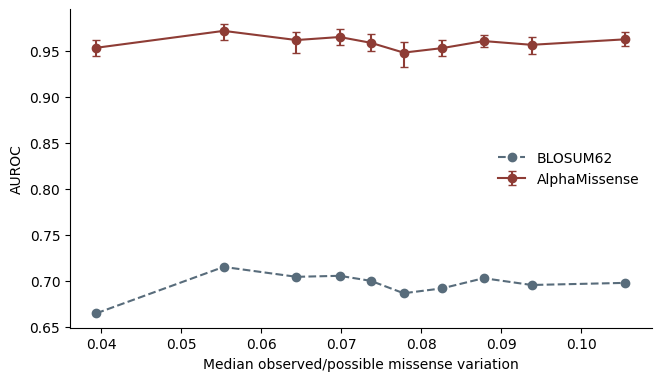

The published negative screen is retained. No new independent confirmation is asserted.


In [11]:
curve=pd.DataFrame(replayed['levels']);x=curve['med_saturation'].to_numpy();y=curve['am_auroc'].to_numpy();ci=np.asarray(curve['am_ci95'].tolist())
fig,ax=plt.subplots(figsize=(6.5,3.7),constrained_layout=True)
ax.errorbar(x,y,yerr=[y-ci[:,0],ci[:,1]-y],marker='o',capsize=3,color='#8e3c35',label='AlphaMissense')
ax.plot(x,curve['blosum_auroc'],'o--',color='#586c7b',label='BLOSUM62')
ax.set(xlabel='Median observed/possible missense variation',ylabel='AUROC');ax.spines[['top','right']].set_visible(False);ax.legend(frameon=False)
fig.savefig(OUT/'curve.png',dpi=180);plt.show()
curve.to_csv(OUT/'curve_from_individual_records.csv',index=False)
print('The published negative screen is retained. No new independent confirmation is asserted.')


In [12]:
manifest=[dict(path=p.name,sha256=hashlib.sha256(p.read_bytes()).hexdigest(),bytes=p.stat().st_size) for p in sorted(OUT.glob('*')) if p.is_file() and p.name!='OUTPUT_MANIFEST.json']
(OUT/'OUTPUT_MANIFEST.json').write_text(json.dumps(manifest,indent=2));print(len(manifest),'recomputed outputs saved and hashed.')


5 recomputed outputs saved and hashed.


## Original agent determination

**Rejected.** No monotonic decline: ρ = −0.16, P = 0.6515 across the ten bin medians and AUROCs. Intervals used 400 gene bootstraps.

This measures how many possible amino-acid-changing variants in a gene have actually been observed in a population database. The audit grouped genes by that fraction and compared how well AlphaMissense separated clinically pathogenic from benign variants.

This is the historical determination recorded in the investigation index. It is preserved alongside the actual calculations, including negative results and preparation-only decisions.